# Assignment No. 2 — Data Cleaning and Preprocessing
## Telco Customer Churn Dataset

**Name:** Afifa Jabbar  
**Roll No:** SU92-BSCSM-F25-012  
**Course:** Introduction To Data Science

---
**How this notebook is organised:** every numbered section has the same pattern —
**code → output → what I found → Decision (what I did and why).**

# 1. Importing Libraries

In [41]:
import os, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (StandardScaler, OneHotEncoder,
                                   OrdinalEncoder, FunctionTransformer)

pd.set_option('display.max_columns', 50)
plt.rcParams['figure.figsize'] = (7, 4)
print("Libraries loaded successfully")

Libraries loaded successfully
The history saving thread hit an unexpected error (OperationalError('attempt to write a readonly database')).History will not be written to the database.


I imported **pandas/numpy** for data handling, **matplotlib** for graphs, and **scikit-learn** for splitting,
encoding and scaling.

# 2. Loading the Dataset

In [42]:
# On Kaggle the CSV is inside /kaggle/input. On Colab/local, place the CSV next to this notebook.
paths = glob.glob('/kaggle/input/**/*Telco*Churn*.csv', recursive=True) + glob.glob('*Telco*Churn*.csv')
print("Found file:", paths[0])
df = pd.read_csv(paths[0])

Found file: /kaggle/input/datasets/blastchar/telco-customer-churn/WA_Fn-UseC_-Telco-Customer-Churn.csv


# 3. Dataset Description

**Dataset Title:** Telco Customer Churn  
**Source:** Kaggle  
**Dataset Link:** https://www.kaggle.com/datasets/blastchar/telco-customer-churn  
**Dataset Size:** 7,043 rows and 21 columns (confirmed in Section 4).  
**Main Features:** customer profile (`gender`, `SeniorCitizen`, `Partner`, `Dependents`), how long they stayed (`tenure`),
services used (phone, internet, security, streaming...), billing (`Contract`, `PaymentMethod`, `MonthlyCharges`, `TotalCharges`).  
**Target Variable:** `Churn` (did the customer leave? Yes/No).  
**Objective:** A telecom company wants to predict which customers will leave so it can try to keep them.
This assignment focuses on **cleaning and preprocessing** the data, not on building the prediction model.

# 4. First Look at the Data

In [43]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [44]:
df.shape

(7043, 21)

In [45]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

**Finding:** The dataset has **7,043 rows and 21 columns**. Each row is one customer.

**Decision:** No change yet. Next I inspect data types and summary statistics.

# 5. Dataset Information and Summary Statistics

In [46]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [47]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


**Finding:** Most columns are `object` (text). `SeniorCitizen`, `tenure` and `MonthlyCharges` are numeric.
`describe()` only shows 3 numeric columns, which means **`TotalCharges` is not being treated as a number** — it must be
stored as text even though it contains money amounts. This is a data-type problem to fix in Section 11.

**Decision:** Investigate `TotalCharges` carefully in the missing-value and data-type sections.

# 6. Target Variable Distribution

Churn
No     5174
Yes    1869
Name: count, dtype: int64
Churn
No     73.5
Yes    26.5
Name: proportion, dtype: float64


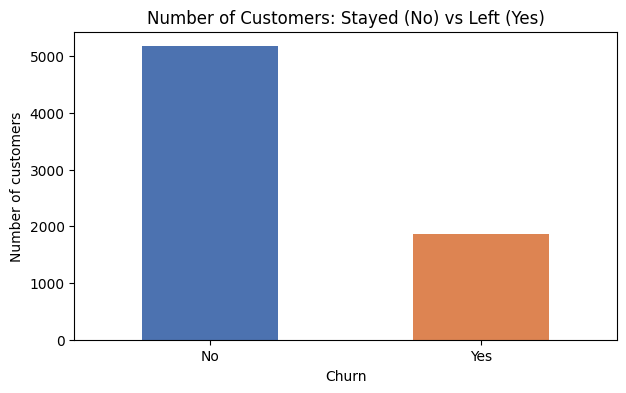

In [48]:
churn_counts = df['Churn'].value_counts()
print(churn_counts)
print((df['Churn'].value_counts(normalize=True) * 100).round(1))

churn_counts.plot(kind='bar', color=['#4C72B0', '#DD8452'])
plt.title('Number of Customers: Stayed (No) vs Left (Yes)')
plt.xlabel('Churn'); plt.ylabel('Number of customers')
plt.xticks(rotation=0)
plt.show()

**Finding:** About **73%** of customers stayed and about **27%** left. The classes are **imbalanced**.

**Decision:** When I split the data later I will use `stratify=y` so that the training and test sets keep the same
73/27 proportion.

# 7. Missing Values Analysis

In [49]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

**Finding:** Pandas reports **0 missing values** in every column. But pandas only counts true `NaN` values.
Missing data can also hide as blank text such as `" "`. I check every text column for this.

In [50]:
for col in df.select_dtypes(include='object').columns:
    n_blank = (df[col].astype(str).str.strip() == '').sum()
    if n_blank > 0:
        print(f"{col}: {n_blank} blank values")

TotalCharges: 11 blank values


In [51]:
blank_rows = df[df['TotalCharges'].str.strip() == '']
blank_rows[['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']]

,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


**Finding:** `TotalCharges` has **11 hidden blank values**, and in every one of those rows `tenure` is **0**.
These are brand-new customers who have not been billed yet. This also explains why the column was stored as text.

**Decision:** I will fill these blanks with **0** (done in Section 11 together with the type conversion).
I do not use the mean or median because the blank has a real meaning: 0 months of service means 0 paid so far.
Deleting the rows would lose 11 valid customers, and the average (about \$2,300) would be a wrong value for them.

# 8. Duplicate Records Analysis

In [52]:
print("Fully duplicated rows:", df.duplicated().sum())
print("Duplicate customerIDs:", df['customerID'].duplicated().sum())

Fully duplicated rows: 0
Duplicate customerIDs: 0


**Finding:** There are **0 duplicate rows** and every `customerID` is unique.

**Decision:** No records need to be removed, so all 7,043 rows are kept. I still run `drop_duplicates()` below as a
safety step. I only remove *exact* duplicates, because two different customers can legitimately have the same plan and charges.

In [53]:
before = len(df)
df = df.drop_duplicates()
print(f"Rows before: {before} | rows after: {len(df)}")

Rows before: 7043 | rows after: 7043


# 9. Categorical Values Inspection

In [54]:
for col in df.select_dtypes(include='object').columns:
    if col not in ['customerID', 'TotalCharges']:
        print(f"{col}: {df[col].unique().tolist()}")

gender: ['Female', 'Male']
Partner: ['Yes', 'No']
Dependents: ['No', 'Yes']
PhoneService: ['No', 'Yes']
MultipleLines: ['No phone service', 'No', 'Yes']
InternetService: ['DSL', 'Fiber optic', 'No']
OnlineSecurity: ['No', 'Yes', 'No internet service']
OnlineBackup: ['Yes', 'No', 'No internet service']
DeviceProtection: ['No', 'Yes', 'No internet service']
TechSupport: ['No', 'Yes', 'No internet service']
StreamingTV: ['No', 'Yes', 'No internet service']
StreamingMovies: ['No', 'Yes', 'No internet service']
Contract: ['Month-to-month', 'One year', 'Two year']
PaperlessBilling: ['Yes', 'No']
PaymentMethod: ['Electronic check', 'Mailed check', 'Bank transfer (automatic)', 'Credit card (automatic)']
Churn: ['No', 'Yes']


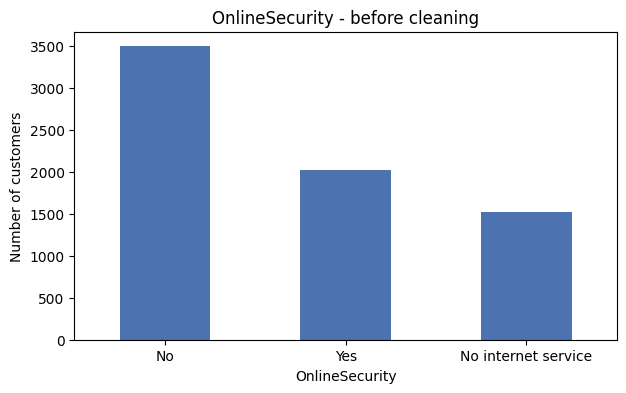

In [55]:
# Bar graph of one service column BEFORE cleaning
df['OnlineSecurity'].value_counts().plot(kind='bar', color='#4C72B0')
plt.title('OnlineSecurity - before cleaning')
plt.ylabel('Number of customers')
plt.xticks(rotation=0)
plt.show()

**Finding:** Six service columns (`OnlineSecurity`, `OnlineBackup`, `DeviceProtection`, `TechSupport`, `StreamingTV`,
`StreamingMovies`) have **three** categories: `Yes`, `No`, and `No internet service`. `MultipleLines` has
`No phone service`. The graph above shows the third category clearly.
"No internet service" means the customer does not have the service, which is the same as "No". The reason is
already stored in `InternetService` / `PhoneService`.

**Decision:** Merge `No internet service` and `No phone service` into **`No`**. This removes redundant categories and
turns these columns into proper Yes/No (binary) columns.

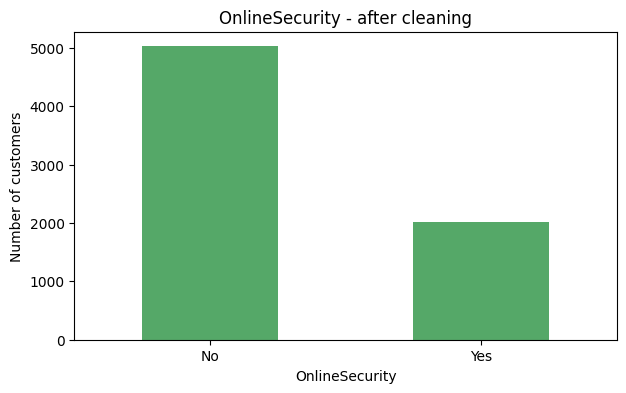

MultipleLines ['No', 'Yes']
OnlineSecurity ['No', 'Yes']
OnlineBackup ['Yes', 'No']
DeviceProtection ['No', 'Yes']
TechSupport ['No', 'Yes']
StreamingTV ['No', 'Yes']
StreamingMovies ['No', 'Yes']


In [56]:
service_cols = ['MultipleLines', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
                'TechSupport', 'StreamingTV', 'StreamingMovies']

df[service_cols] = df[service_cols].replace({'No internet service': 'No', 'No phone service': 'No'})

df['OnlineSecurity'].value_counts().plot(kind='bar', color='#55A868')
plt.title('OnlineSecurity - after cleaning')
plt.ylabel('Number of customers')
plt.xticks(rotation=0)
plt.show()

for col in service_cols:
    print(col, df[col].unique().tolist())

**Result:** Every service column now has only `Yes` and `No`.

**Second inconsistency:** `SeniorCitizen` is stored as 0/1 while all other Yes/No columns use words.

**Decision:** Convert `SeniorCitizen` to `Yes`/`No` so all binary columns share the same format.

In [57]:
df['SeniorCitizen'] = df['SeniorCitizen'].map({0: 'No', 1: 'Yes'})
df['SeniorCitizen'].value_counts()

SeniorCitizen
No     5901
Yes    1142
Name: count, dtype: int64

# 10. Cleaning Text Formatting

In [58]:
# Remove accidental leading/trailing spaces in every text column
for col in df.select_dtypes(include='object').columns:
    df[col] = df[col].str.strip()
print("Whitespace removed from all text columns")

Whitespace removed from all text columns


**Decision:** I strip spaces from all text columns so that `"Yes "` and `"Yes"` can never be treated as different values.
This is a standard safety step. (It also turns the blank `" "` values in `TotalCharges` into empty strings, which are easy to convert.)

# 11. Data Types Analysis and Correction

In [59]:
df.dtypes

customerID           object
gender               object
SeniorCitizen        object
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object

In [60]:
# Convert TotalCharges to numeric. errors='coerce' turns blank strings into NaN.
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
print("Missing TotalCharges after conversion:", df['TotalCharges'].isnull().sum())

# Fill with 0 - but first prove this is valid: all missing rows must have tenure == 0
assert (df.loc[df['TotalCharges'].isnull(), 'tenure'] == 0).all()
df['TotalCharges'] = df['TotalCharges'].fillna(0)

print("Missing TotalCharges after filling:", df['TotalCharges'].isnull().sum())
print("New data type:", df['TotalCharges'].dtype)

Missing TotalCharges after conversion: 11
Missing TotalCharges after filling: 0
New data type: float64


**Finding:** `TotalCharges` was stored as `object` (text) although it is a money amount.

**Decision:** Convert it to `float64` with `pd.to_numeric(..., errors='coerce')`, then fill the 11 resulting blanks with 0.
The `assert` line proves in code that every filled row has `tenure == 0`, so the fill is justified.
This fixes the missing-value problem (Section 7) and the data-type problem together.

`SeniorCitizen` was also an incorrect type (a number that is really a category) and was fixed in Section 9.
`tenure` and `MonthlyCharges` already have correct numeric types.

In [61]:
df.dtypes

customerID           object
gender               object
SeniorCitizen        object
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges        float64
Churn                object
dtype: object

# 12. Removing the Identifier Column

In [62]:
df = df.drop(columns=['customerID'])
print("Shape now:", df.shape)

Shape now: (7043, 20)


**Decision:** `customerID` is only a unique label. It holds no pattern about why customers leave, and a model could
memorise it instead of learning real relationships. I dropped it (21 → 20 columns).

# 13. Numerical Data Summary

In [63]:
df[['tenure', 'MonthlyCharges', 'TotalCharges']].describe()

,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000
mean,32.371149,64.761692,2279.734304
std,24.559481,30.090047,2266.794470
min,0.000000,18.250000,0.000000
25%,9.000000,35.500000,398.550000
50%,29.000000,70.350000,1394.550000
75%,55.000000,89.850000,3786.600000
max,72.000000,118.750000,8684.800000


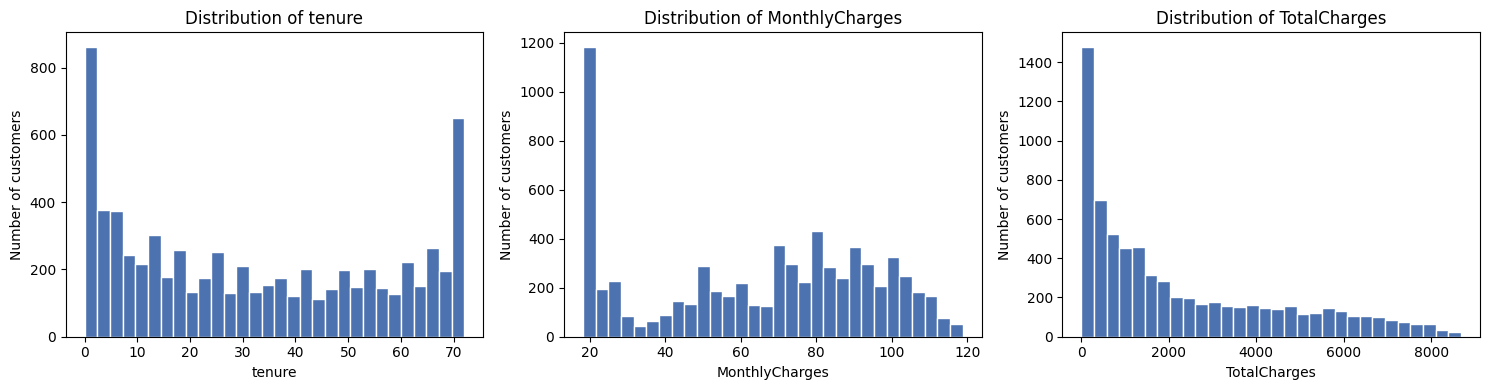

In [64]:
num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, num_cols):
    ax.hist(df[col], bins=30, color='#4C72B0', edgecolor='white')
    ax.set_title(f'Distribution of {col}')
    ax.set_xlabel(col); ax.set_ylabel('Number of customers')
plt.tight_layout()
plt.show()

**Finding:** `tenure` is between 0 and 72 months and `MonthlyCharges` between about \$18 and \$119, both realistic.
`TotalCharges` is now included in the summary (the type fix worked) and its histogram has a long tail to the right —
a sign of **skewness**, handled in Section 22.

**Decision:** All values are within realistic ranges, so no value is invalid.

# 14. Outlier Analysis Using the IQR Method

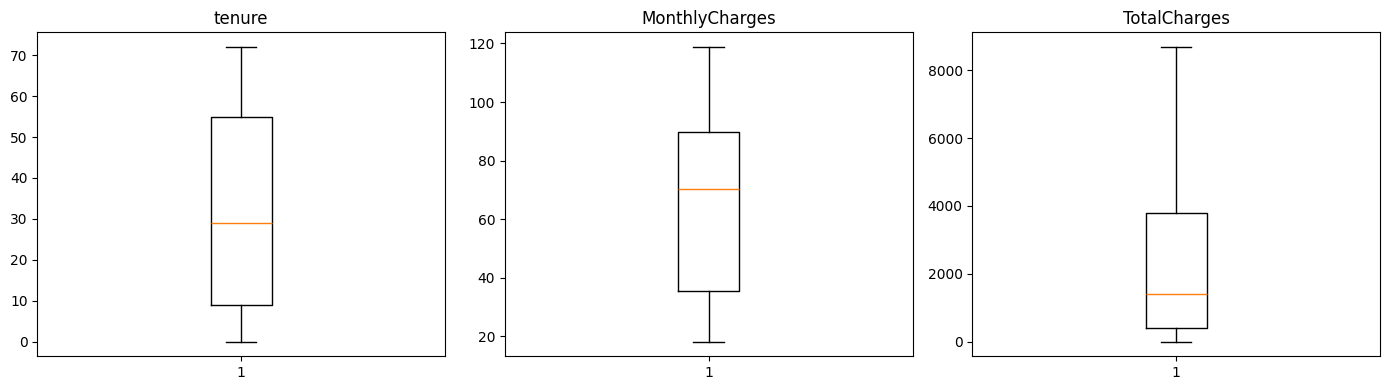

In [65]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, num_cols):
    ax.boxplot(df[col])
    ax.set_title(col)
plt.tight_layout()
plt.show()

In [66]:
rows = []
for col in num_cols:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((df[col] < low) | (df[col] > high)).sum()
    rows.append([col, q1, q3, iqr, low, high, n_out])
pd.DataFrame(rows, columns=['column', 'Q1', 'Q3', 'IQR', 'lower_bound', 'upper_bound', 'n_outliers'])

,column,Q1,Q3,IQR,lower_bound,upper_bound,n_outliers
0,tenure,9.00,55.00,46.00,-60.000,124.000,0
1,MonthlyCharges,35.50,89.85,54.35,-46.025,171.375,0
2,TotalCharges,398.55,3786.60,3388.05,-4683.525,8868.675,0


**Finding:** The IQR rule flags no (or almost no) values as outliers in these three columns, and the boxplots show
no points far outside the whiskers.

**Decision:** I **keep all values**. An outlier should only be removed when it is an error. Here every value is realistic,
so deleting any would remove real customers. The right-skew of `TotalCharges` is handled with a transformation instead
(Section 22).

# 15. Exploring Churn Across Categories (Bar Graphs)

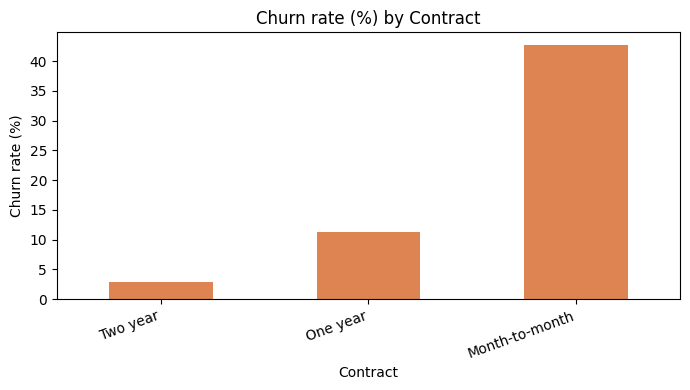

Contract
Two year           2.8
One year          11.3
Month-to-month    42.7
Name: Churn, dtype: float64

In [67]:
def churn_rate_bar(col, color='#DD8452'):
    rate = df.groupby(col)['Churn'].apply(lambda s: (s == 'Yes').mean() * 100).sort_values()
    rate.plot(kind='bar', color=color)
    plt.title(f'Churn rate (%) by {col}')
    plt.ylabel('Churn rate (%)')
    plt.xticks(rotation=20, ha='right')
    plt.tight_layout()
    plt.show()
    return rate.round(1)

churn_rate_bar('Contract')

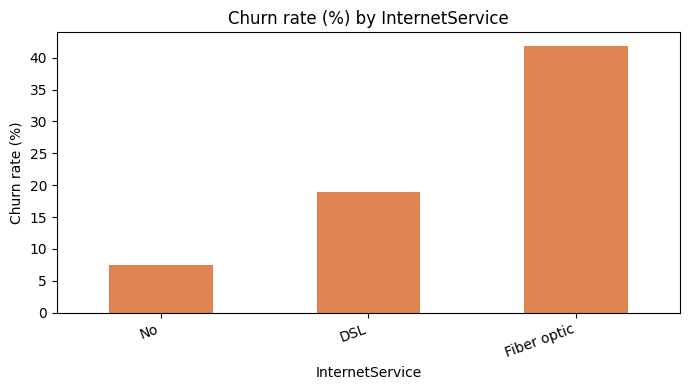

InternetService
No              7.4
DSL            19.0
Fiber optic    41.9
Name: Churn, dtype: float64

In [68]:
churn_rate_bar('InternetService')

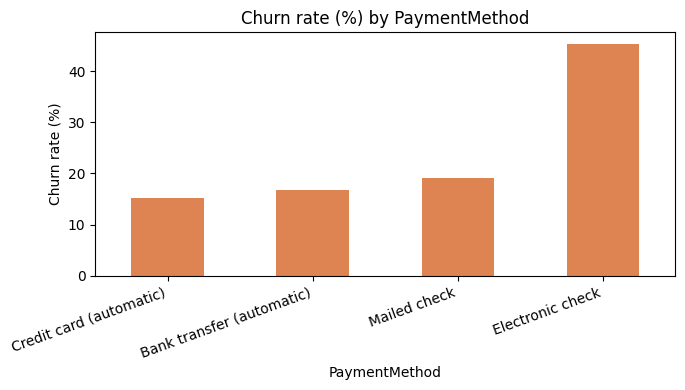

PaymentMethod
Credit card (automatic)      15.2
Bank transfer (automatic)    16.7
Mailed check                 19.1
Electronic check             45.3
Name: Churn, dtype: float64

In [69]:
churn_rate_bar('PaymentMethod')

**Finding:** Churn is not equal across groups. Month-to-month customers leave much more than customers with
one- or two-year contracts, and fibre-optic and electronic-check customers also leave more often.

**Decision:** These graphs are for **understanding only**; I did not change any data here. They confirm that
`Contract`, `InternetService` and `PaymentMethod` carry useful information, so I keep them as features.
`Contract` is clearly **ordered** (longer contract = lower churn), which supports encoding it as an ordinal variable later.

# 16. Identifying Features and Target

In [70]:
y = df['Churn'].map({'No': 0, 'Yes': 1})
X = df.drop(columns=['Churn'])
print("Features shape:", X.shape)
print("Target counts (0 = stayed, 1 = left):")
print(y.value_counts())

Features shape: (7043, 19)
Target counts (0 = stayed, 1 = left):
Churn
0    5174
1    1869
Name: count, dtype: int64


**Decision:** The **target** is `Churn`, converted to 1 (left) / 0 (stayed) because models need numbers.
The **features** are the other 19 columns.

**Leakage note:** Because `Churn` is the target, **no feature may be created from it**. Every new feature below
uses only the customer's own non-target columns.

# 17. Identifying Variable Types

| Type | Columns | Why |
|---|---|---|
| **Numerical** | `tenure`, `MonthlyCharges`, `TotalCharges` | real measured numbers |
| **Binary** | `gender`, `SeniorCitizen`, `Partner`, `Dependents`, `PhoneService`, `PaperlessBilling`, `MultipleLines`, `OnlineSecurity`, `OnlineBackup`, `DeviceProtection`, `TechSupport`, `StreamingTV`, `StreamingMovies` | exactly two values |
| **Ordinal** | `Contract` | natural order: Month-to-month < One year < Two year |
| **Nominal** | `InternetService`, `PaymentMethod` | categories with no ranking |
| **Date/Time** | none | no date column exists (`tenure` is a count of months, so it is numeric) |
| **Target** | `Churn` | what we predict |

In [71]:
binary_cols  = ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService',
                'PaperlessBilling'] + service_cols
ordinal_cols = ['Contract']
nominal_cols = ['InternetService', 'PaymentMethod']
numeric_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']

print("Every feature assigned to exactly one group:",
      sorted(binary_cols + ordinal_cols + nominal_cols + numeric_cols) == sorted(X.columns))

Every feature assigned to exactly one group: True


# 18. Feature Engineering

New features are calculated **row by row** from the same customer's own data, so creating them before the split does
**not** leak information.

| New feature | Formula | Why useful |
|---|---|---|
| `AvgMonthlySpend` | `TotalCharges / tenure` | real average paid per month |
| `NumServices` | number of "Yes" among 6 add-on services | more services may mean stronger attachment |
| `HasFamily` | `Partner` or `Dependents` is Yes | customers with family may switch less |

In [72]:
addon_cols = ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
              'TechSupport', 'StreamingTV', 'StreamingMovies']

# tenure = 0 would cause division by zero -> use MonthlyCharges for those new customers
X['AvgMonthlySpend'] = np.where(X['tenure'] > 0,
                                X['TotalCharges'] / X['tenure'].replace(0, np.nan),
                                X['MonthlyCharges'])
X['NumServices'] = (X[addon_cols] == 'Yes').sum(axis=1)
X['HasFamily'] = ((X['Partner'] == 'Yes') | (X['Dependents'] == 'Yes')).map({True: 'Yes', False: 'No'})

numeric_cols = numeric_cols + ['AvgMonthlySpend', 'NumServices']
binary_cols  = binary_cols + ['HasFamily']

X[['tenure', 'TotalCharges', 'AvgMonthlySpend', 'NumServices', 'HasFamily']].head()

,tenure,TotalCharges,AvgMonthlySpend,NumServices,HasFamily
0,1,29.85,29.850000,1,Yes
1,34,1889.50,55.573529,2,No
2,2,108.15,54.075000,2,No
3,45,1840.75,40.905556,3,No
4,2,151.65,75.825000,0,No


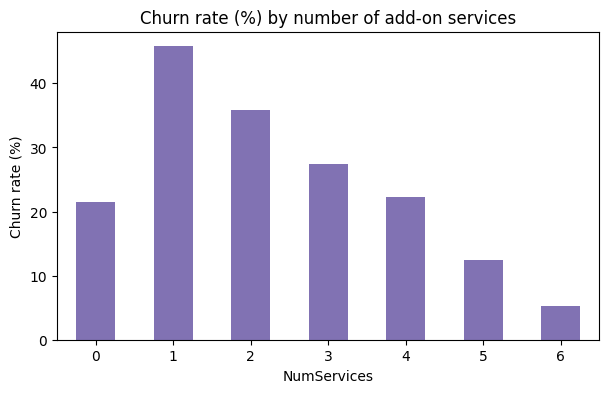

In [73]:
# Does the new feature relate to churn?  (graph only - nothing is fitted here)
tmp = pd.DataFrame({'NumServices': X['NumServices'], 'Churn': y})
tmp.groupby('NumServices')['Churn'].mean().mul(100).plot(kind='bar', color='#8172B3')
plt.title('Churn rate (%) by number of add-on services')
plt.ylabel('Churn rate (%)'); plt.xlabel('NumServices')
plt.xticks(rotation=0)
plt.show()

**Decision:** I kept all three features. The graph shows churn changes with the number of services, so
`NumServices` carries useful information. For `AvgMonthlySpend`, customers with `tenure = 0` use their
`MonthlyCharges`, which avoids dividing by zero.

# 19. Train-Test Split (Before Any Scaling or Encoding)

**This is the key step for avoiding data leakage.** If I scaled or encoded the whole dataset first, the mean, standard
deviation and categories would include information from the test rows. So I split **first**, learn every statistic
**only from the training set**, and then apply it to the test set.

In [74]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Churn rate  train:", round(y_train.mean(), 3), "| test:", round(y_test.mean(), 3))

Train: (5634, 22) | Test: (1409, 22)
Churn rate  train: 0.265 | test: 0.265


**Decision:** 80% training / 20% testing. `random_state=42` makes the split reproducible and `stratify=y` keeps the churn
rate almost identical in both parts (shown above).

# 20. Skewness Analysis (Training Set Only)

tenure             0.24
MonthlyCharges    -0.22
TotalCharges       0.95
AvgMonthlySpend   -0.21
NumServices        0.44
dtype: float64


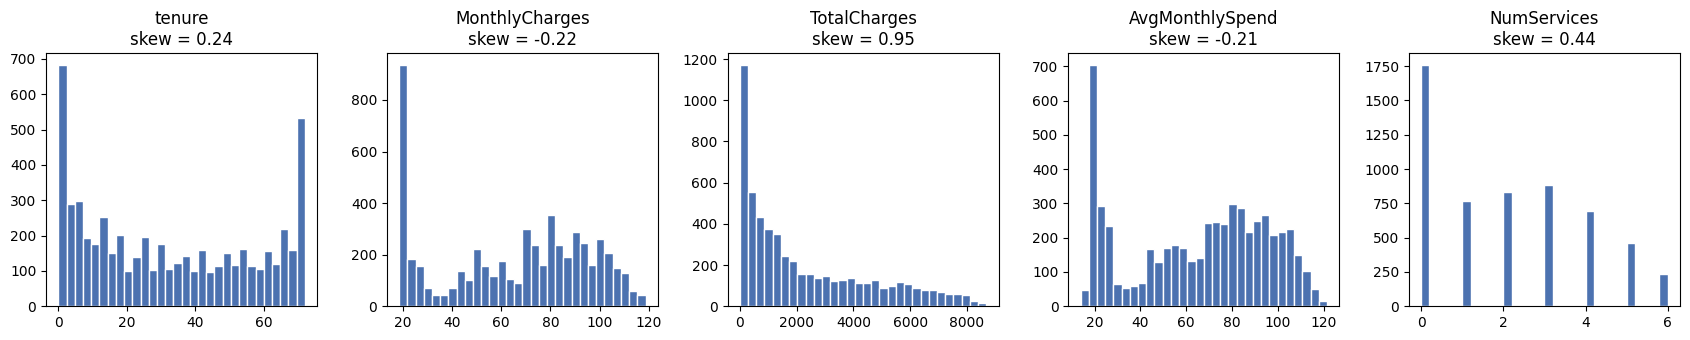

In [75]:
skew_values = X_train[numeric_cols].skew().round(2)
print(skew_values)

fig, axes = plt.subplots(1, len(numeric_cols), figsize=(17, 3.5))
for ax, col in zip(axes, numeric_cols):
    ax.hist(X_train[col], bins=30, color='#4C72B0', edgecolor='white')
    ax.set_title(f"{col}\nskew = {skew_values[col]}")
plt.tight_layout()
plt.show()

**Finding:** A skewness near 0 means a symmetric shape. A value above about **0.75** (or below -0.75) is
noticeably skewed. `TotalCharges` is **right-skewed**: most customers have small totals and a few have very large ones.

**Decision:** Apply a **log transformation** to strongly skewed columns. I use `log1p` (log of 1 + x) instead of plain
`log` because `TotalCharges` contains zeros, and `log(0)` is undefined. The columns to transform are selected
automatically from the **training-set** skewness.

# 21. Applying the Transformation

Log-transformed columns: ['TotalCharges']
Only standardized columns: ['tenure', 'MonthlyCharges', 'AvgMonthlySpend', 'NumServices']


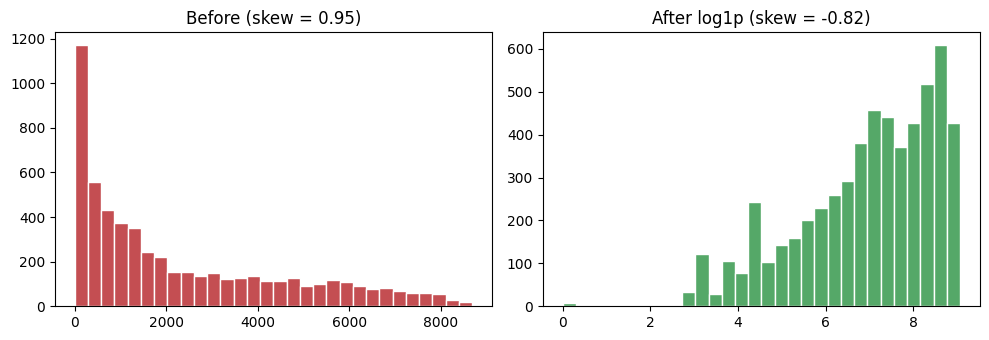

In [76]:
skewed_cols = [c for c in numeric_cols if abs(X_train[c].skew()) > 0.75]
normal_cols = [c for c in numeric_cols if c not in skewed_cols]
print("Log-transformed columns:", skewed_cols)
print("Only standardized columns:", normal_cols)

if 'TotalCharges' in skewed_cols:
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
    axes[0].hist(X_train['TotalCharges'], bins=30, color='#C44E52', edgecolor='white')
    axes[0].set_title(f"Before (skew = {X_train['TotalCharges'].skew():.2f})")
    axes[1].hist(np.log1p(X_train['TotalCharges']), bins=30, color='#55A868', edgecolor='white')
    axes[1].set_title(f"After log1p (skew = {np.log1p(X_train['TotalCharges']).skew():.2f})")
    plt.tight_layout()
    plt.show()

**Finding:** After `log1p` the distribution is much closer to symmetric and the skewness value moves closer to 0.

**Decision:** Keep the log transformation for the skewed column(s). The transformation is placed inside the
preprocessing pipeline (Section 23) so it is applied consistently to training and test data.

# 22. Choosing Encoding and Scaling Methods

| Variable type | Method | Why |
|---|---|---|
| Binary | `OneHotEncoder(drop='if_binary')` → one 0/1 column | Yes/No becomes 1/0 with no extra column |
| Ordinal (`Contract`) | `OrdinalEncoder` with manual order (0,1,2) | keeps the order Month-to-month < One year < Two year |
| Nominal | `OneHotEncoder` | no order exists; numbers 1,2,3 would create a false ranking |
| Skewed numeric | `log1p` → `StandardScaler` | reduce skew, then equal scale |
| Other numeric | `StandardScaler` | mean 0, standard deviation 1 |

**Why standardization (not min-max)?** There are no extreme outliers to worry about, and many models
(logistic regression, SVM, KNN) work best when features are centred with similar spread.

# 23. Building and Applying the Preprocessing Pipeline

In [77]:
log_then_scale = Pipeline([
    ('log', FunctionTransformer(np.log1p, feature_names_out='one-to-one')),
    ('scale', StandardScaler())
])

preprocessor = ColumnTransformer(transformers=[
    ('num_skewed', log_then_scale, skewed_cols),
    ('num_normal', StandardScaler(), normal_cols),
    ('binary',  OneHotEncoder(drop='if_binary', sparse_output=False), binary_cols),
    ('ordinal', OrdinalEncoder(categories=[['Month-to-month', 'One year', 'Two year']]), ordinal_cols),
    ('nominal', OneHotEncoder(handle_unknown='ignore', sparse_output=False), nominal_cols),
])

# FIT on training data only, TRANSFORM both sets
X_train_proc = preprocessor.fit_transform(X_train)
X_test_proc  = preprocessor.transform(X_test)

names = preprocessor.get_feature_names_out()
X_train_proc = pd.DataFrame(X_train_proc, columns=names, index=X_train.index)
X_test_proc  = pd.DataFrame(X_test_proc,  columns=names, index=X_test.index)

print("Processed train shape:", X_train_proc.shape)
print("Processed test shape: ", X_test_proc.shape)
X_train_proc.head()

Processed train shape: (5634, 27)
Processed test shape:  (1409, 27)


,num_skewed__TotalCharges,num_normal__tenure,num_normal__MonthlyCharges,num_normal__AvgMonthlySpend,num_normal__NumServices,binary__gender_Male,binary__SeniorCitizen_Yes,binary__Partner_Yes,binary__Dependents_Yes,binary__PhoneService_Yes,binary__PaperlessBilling_Yes,binary__MultipleLines_Yes,binary__OnlineSecurity_Yes,binary__OnlineBackup_Yes,binary__DeviceProtection_Yes,binary__TechSupport_Yes,binary__StreamingTV_Yes,binary__StreamingMovies_Yes,binary__HasFamily_Yes,ordinal__Contract,nominal__InternetService_DSL,nominal__InternetService_Fiber optic,nominal__InternetService_No,nominal__PaymentMethod_Bank transfer (automatic),nominal__PaymentMethod_Credit card (automatic),nominal__PaymentMethod_Electronic check,nominal__PaymentMethod_Mailed check
3738,0.316915,0.102371,-0.521976,-0.539986,0.507935,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
3151,0.067683,-0.711743,0.337478,0.391496,-0.570530,1.0,0.0,1.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
4860,-0.358545,-0.793155,-0.809013,-0.646102,0.507935,1.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0,1.0,2.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
3867,0.389209,-0.263980,0.284384,0.276552,1.047168,0.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0,2.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
3810,-1.995946,-1.281624,-0.676279,-0.674608,-1.109762,1.0,0.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0


**Finding:** The original text and numeric columns are now one fully numeric table.

**Decision:** `fit_transform` is called on **X_train only**, and `transform` on X_test. The scaler, the log
selection and the encoders therefore learn nothing from the test data.

# 24. Verification of the Processed Data

In [78]:
print("Missing values in train:", X_train_proc.isnull().sum().sum())
print("Missing values in test: ", X_test_proc.isnull().sum().sum())
print("All columns numeric:", all(np.issubdtype(t, np.number) for t in X_train_proc.dtypes))

scaled = [c for c in X_train_proc.columns if c.startswith(('num_skewed__', 'num_normal__'))]
print("\nTRAIN scaled columns (expect mean ~0, std ~1):")
print(X_train_proc[scaled].agg(['mean', 'std']).round(3))
print("\nTEST scaled columns (close to, but NOT exactly, 0 and 1):")
print(X_test_proc[scaled].agg(['mean', 'std']).round(3))

Missing values in train: 0
Missing values in test:  0
All columns numeric: True

TRAIN scaled columns (expect mean ~0, std ~1):
      num_skewed__TotalCharges  num_normal__tenure  \
mean                      -0.0                -0.0   
std                        1.0                 1.0   

      num_normal__MonthlyCharges  num_normal__AvgMonthlySpend  \
mean                        -0.0                         -0.0   
std                          1.0                          1.0   

      num_normal__NumServices  
mean                      0.0  
std                       1.0  

TEST scaled columns (close to, but NOT exactly, 0 and 1):
      num_skewed__TotalCharges  num_normal__tenure  \
mean                    -0.036              -0.023   
std                      1.011               0.998   

      num_normal__MonthlyCharges  num_normal__AvgMonthlySpend  \
mean                      -0.028                       -0.029   
std                        0.992                        0.994   


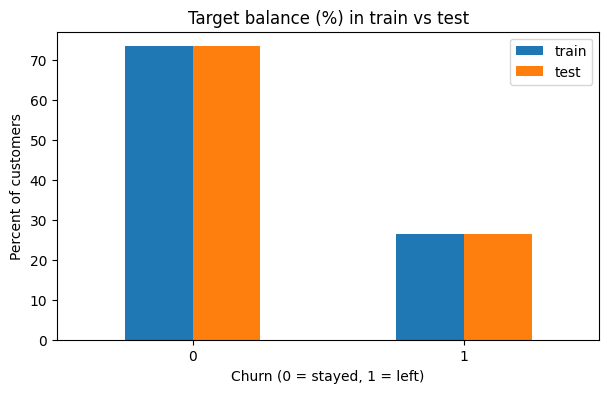

In [79]:
# Bar graph: the final target balance in train vs test
pd.DataFrame({'train': y_train.value_counts(normalize=True),
              'test':  y_test.value_counts(normalize=True)}).mul(100).plot(kind='bar')
plt.title('Target balance (%) in train vs test')
plt.ylabel('Percent of customers'); plt.xlabel('Churn (0 = stayed, 1 = left)')
plt.xticks(rotation=0)
plt.show()

**Finding:** No missing values remain, every column is numeric, and the training columns have mean ≈ 0 and
standard deviation ≈ 1. The test columns are *close* but not exactly 0 and 1.

**Decision / explanation:** This difference is expected and correct. The test set was scaled with the **training**
mean and standard deviation. If the test set were exactly 0 and 1, it would prove that I had fitted the scaler on test data
(data leakage). The last graph also confirms train and test have the same class balance.

# 25. Saving the Processed Files

In [80]:
os.makedirs('processed_data', exist_ok=True)
df.to_csv('processed_data/telco_cleaned.csv', index=False)
X_train_proc.to_csv('processed_data/X_train_processed.csv', index=False)
X_test_proc.to_csv('processed_data/X_test_processed.csv', index=False)
y_train.to_csv('processed_data/y_train.csv', index=False)
y_test.to_csv('processed_data/y_test.csv', index=False)
print("Saved:", os.listdir('processed_data'))

Saved: ['y_test.csv', 'X_train_processed.csv', 'X_test_processed.csv', 'y_train.csv', 'telco_cleaned.csv']


**Decision:** I saved the cleaned dataset and the preprocessed train/test files so the work can be reused for model building.

# 26. Summary of All Cleaning and Preprocessing Decisions

| Step | Problem found | What I did | Why |
|---|---|---|---|
| Missing values | 11 hidden blanks in `TotalCharges` (all tenure = 0) | filled with 0 | blank means "not billed yet" |
| Duplicates | none | `drop_duplicates()` as a check | safety step |
| Inconsistent categories | "No internet service" / "No phone service"; `SeniorCitizen` as 0/1 | merged into "No"; mapped to Yes/No | remove redundancy, consistent binary format |
| Text formatting | possible stray spaces | stripped whitespace | avoid fake categories |
| Data types | `TotalCharges` stored as text | converted to float | it is a numeric amount |
| Identifier | `customerID` | dropped | no pattern, could be memorised |
| Outliers | none that are errors | kept all values | they are real customers |
| Skewness | `TotalCharges` right-skewed | `log1p` transform | reduce skew, safe with zeros |
| Encoding | text columns | binary / ordinal / one-hot | match each variable type |
| Scaling | different numeric ranges | `StandardScaler` | equal influence on models |
| Feature engineering | – | `AvgMonthlySpend`, `NumServices`, `HasFamily` | add useful information |
| Data leakage | – | split first, fit only on train | keep the test set unseen |

# 27. Conclusion

The Telco Customer Churn dataset looked clean at first (`isnull()` reported no missing values), but careful inspection
found hidden blank values and a wrongly typed column, plus redundant categories. I fixed each problem and
explained the reason for every decision.

I then separated the features from the target `Churn`, created three new features, **split the data before any fitting**,
and used a pipeline that applies the log transformation, encoding and scaling using only training-set statistics.

**Important note on leakage:** `Churn` is the target, so it was never used to create features or to decide any
transformation parameter. The result is a clean, fully numeric dataset that is ready for building a churn prediction model.